# 2013. Detect Squares
**Difficulty:** 🟡 Medium · **Topic:** Arrays and Hashing · **Pattern:** [Frequency Count](README.md) · **LeetCode:** https://leetcode.com/problems/detect-squares/

## 💡 Concepts

**Core concept(s):** **Frequency count of points** — a hash map from `(x, y)` to how many times that point was added.

**Why it applies here:**
- A square is fixed once you know the query point and the corner **diagonally opposite** it.
- The other two corners are then forced: `(qx, py)` and `(px, qy)`.
- So the question "how many squares?" becomes "how many copies of each of those three corners exist?", and a count map answers each of those in O(1).
- Duplicate points count as different points, so the counts **multiply**: 2 copies of one corner × 1 copy of another = 2 squares.

**Key intuition:**
- Don't search for squares. Try each stored point as the diagonal corner, and read the other two corners' counts from the map.

---

### 📚 What is a Hash Map (and `Counter`)?
- A **hash map** (Python `dict`) stores key → value pairs.
- It runs each key through a *hash function* to pick a slot, so it jumps straight to the value instead of scanning.
- Insert, lookup, and update are **O(1) on average**.
- A **frequency count** is a hash map whose value is "how many times have I seen this key".
- **In Python:** `collections.Counter` is a `dict` made for counting. `cnt[key] += 1` tallies, and reading a missing key returns `0` *without inserting it*.
- The key must be hashable: a `tuple` like `(3, 10)` works, a `list` like `[3, 10]` does not.

### 📚 What is an axis-aligned square?
- A square whose sides are horizontal and vertical (parallel to the x- and y-axes).
- Two opposite corners `(qx, qy)` and `(px, py)` are diagonal exactly when `|px - qx| == |py - qy|`.
- **Positive area** means the side is not 0, so `px != qx` is required.
- The remaining corners are `(qx, py)` (same column as the query) and `(px, qy)` (same row as the query).

### 📚 What is a design problem?
- Instead of one function, you implement a **class** whose methods are called many times in some order.
- Here: `add(point)` and `count(point)`, called up to 3000 times in total.
- The trade-off is where the work goes: cheap `add` with expensive `count`, or a little bookkeeping in `add` so `count` is fast.

---

**Prerequisite knowledge:**
- Counting with a `dict` / `Counter` (see [Valid Anagram](valid_anagram.ipynb)).
- Coordinates on a grid.

## 📝 Problem

Design a data structure over points on a 2-D grid:

- `DetectSquares()` creates an empty structure.
- `add(point)` stores a new point `[x, y]`. **Duplicate points are allowed** and are treated as different points.
- `count(point)` returns how many ways you can choose **three stored points** that, together with the query point, form an **axis-aligned square with positive area**.

**Example** (LeetCode)
```
ops  = ["DetectSquares", "add", "add", "add", "count", "count", "add", "count"]
args = [[], [[3,10]], [[11,2]], [[3,2]], [[11,10]], [[14,8]], [[11,2]], [[11,10]]]
out  = [None, None, None, None, 1, 0, None, 2]

 y=10  (3,10) .......... (11,10) <- query
         |                  |
 y=2   (3,2) ........... (11,2)  x2 after the second add
```
- `count([11,10])` → `1`: corners `(3,10)`, `(3,2)`, `(11,2)`.
- `count([14,8])` → `0`: no square.
- After adding `(11,2)` again, `count([11,10])` → `2`: either copy of `(11,2)` can be used.

**Constraints:** `point.length == 2`, `0 <= x, y <= 1000`, at most `3000` calls in total to `add` and `count`.

> Two meaningfully distinct approaches: scan the raw list of points (`O(n²)` per `count`), or keep a point → count map (`O(n)` per `count`). Both `add`s are `O(1)`.

In [1]:
from collections import Counter
from typing import List

def run_ops(cls, ops, args):
    # Replay a LeetCode-style operation list against a class and collect the outputs.
    out, obj = [], None
    for op, a in zip(ops, args):
        if op == "DetectSquares":
            obj = cls(); out.append(None)
        elif op == "add":
            obj.add(a[0]); out.append(None)
        else:                                  # "count"
            out.append(obj.count(a[0]))
    return out

### Approach 1 — Brute Force: keep a plain list, rescan it per corner

**Idea:**
1. `add` appends the point to a list (duplicates stay as separate entries).
2. `count(q)`: try every stored point `p` as the corner diagonally opposite `q`. Skip it unless `|px - qx| == |py - qy|` and `px != qx`.
3. For each diagonal `p`, scan the **whole list** to count copies of `(qx, py)` and of `(px, qy)`, and add their product.

**Time complexity:** `add` `O(1)`; `count` `O(n²)` — up to `n` diagonal candidates, each followed by a full `O(n)` scan of the list.

**Space complexity:** `O(n)` — the list of all added points.

In [2]:
class DetectSquaresBrute:
    def __init__(self):
        self.points = []                         # every added point, duplicates kept as separate entries

    def add(self, point: List[int]) -> None:
        self.points.append(tuple(point))

    def count(self, point: List[int]) -> int:
        qx, qy = point
        res = 0
        for px, py in self.points:               # each stored point as the diagonal corner
            if abs(px - qx) != abs(py - qy) or px == qx:
                continue                         # not a diagonal, or a zero-area "square"
            # The other two corners are forced; count their copies by rescanning the list.
            c1 = sum(1 for p in self.points if p == (qx, py))   # same column as the query
            c2 = sum(1 for p in self.points if p == (px, qy))   # same row as the query
            res += c1 * c2                       # every pairing of copies is a different square
        return res

### Approach 2 — Frequency Count of points (optimal · pattern template)

**Idea:** the [Frequency Count](README.md) template: tally each point as it arrives, then answer `count` by **reading** the tallies.
1. `add` does `cnt[(x, y)] += 1`.
2. `count(q)`: loop over the **distinct** stored points `p` with their multiplicity `n`. Skip `p` unless it is a diagonal corner (`|px - qx| == |py - qy|`, `px != qx`).
3. Add `n * cnt[(qx, py)] * cnt[(px, qy)]` — the number of ways to pick one copy of each of the three corners. A missing corner reads as `0`, so non-squares add nothing.

**Time complexity:** `add` `O(1)`; `count` `O(d)` where `d ≤ n` is the number of distinct points — one pass with `O(1)` lookups.

**Space complexity:** `O(d)` — one map entry per distinct point.

> Why not cheaper? Any `p` could be the diagonal corner, so `count` must look at every distinct point once. With coordinates `≤ 1000` the map holds at most `1001²` keys, but in practice `d ≤ 3000` (the call limit).

In [3]:
class DetectSquares:
    def __init__(self):
        self.cnt = Counter()                     # (x, y) -> how many times that point was added

    def add(self, point: List[int]) -> None:
        self.cnt[tuple(point)] += 1              # O(1) tally; tuple because lists aren't hashable

    def count(self, point: List[int]) -> int:
        qx, qy = point
        res = 0
        for (px, py), n in self.cnt.items():     # each DISTINCT point as the diagonal corner
            if abs(px - qx) != abs(py - qy) or px == qx:
                continue                         # not a diagonal, or zero area
            # Counter returns 0 for a missing corner and does not insert it (safe while iterating).
            res += n * self.cnt[(qx, py)] * self.cnt[(px, qy)]
        return res

In [4]:
# Correctness check
import random

tests = [
    # LeetCode example
    (["DetectSquares", "add", "add", "add", "count", "count", "add", "count"],
     [[], [[3, 10]], [[11, 2]], [[3, 2]], [[11, 10]], [[14, 8]], [[11, 2]], [[11, 10]]],
     [None, None, None, None, 1, 0, None, 2]),
    # Squares in all four directions around the query (5, 5), side 1
    (["DetectSquares"] + ["add"] * 8 + ["count"],
     [[]] + [[p] for p in ([4, 4], [4, 5], [5, 4], [6, 6], [6, 5], [5, 6], [4, 6], [6, 4])] + [[[5, 5]]],
     [None] * 9 + [4]),
    # Duplicates multiply: 2 copies of (0,0) x 2 copies of (1,0) x 1 copy of (0,1)
    (["DetectSquares", "add", "add", "add", "add", "add", "count"],
     [[], [[0, 0]], [[0, 0]], [[1, 0]], [[1, 0]], [[0, 1]], [[1, 1]]],
     [None] * 6 + [4]),
    # Zero area: the same point repeated is not a square
    (["DetectSquares", "add", "add", "add", "count"],
     [[], [[1, 1]], [[1, 1]], [[1, 1]], [[1, 1]]],
     [None] * 4 + [0]),
    # A rectangle that is not a square
    (["DetectSquares", "add", "add", "add", "count"],
     [[], [[0, 0]], [[0, 1]], [[2, 0]], [[2, 1]]],
     [None] * 4 + [0]),
    # Count before anything was added
    (["DetectSquares", "count"], [[], [[0, 0]]], [None, 0]),
]
for ops, args, exp in tests:
    a, b = run_ops(DetectSquaresBrute, ops, args), run_ops(DetectSquares, ops, args)
    print(f"{len(ops):2} ops -> {b}")
    assert a == b == exp, f"mismatch: brute={a} counter={b} expected={exp}"

# Randomised cross-check on a small grid (many duplicates and many squares)
rng = random.Random(2013)
for _ in range(300):
    ops, args = ["DetectSquares"], [[]]
    for _ in range(rng.randint(1, 40)):
        ops.append(rng.choice(["add", "add", "count"]))
        args.append([[rng.randint(0, 5), rng.randint(0, 5)]])
    assert run_ops(DetectSquaresBrute, ops, args) == run_ops(DetectSquares, ops, args), (ops, args)
print("300 random operation lists: both approaches agree")

print("\nAll tests passed")

 8 ops -> [None, None, None, None, 1, 0, None, 2]
10 ops -> [None, None, None, None, None, None, None, None, None, 4]
 7 ops -> [None, None, None, None, None, None, 4]
 5 ops -> [None, None, None, None, 0]
 5 ops -> [None, None, None, None, 0]
 2 ops -> [None, 0]
300 random operation lists: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n²)`       | ≈ **4×** |

**Worst-case input:** `3n` points — the diagonal `(i, i)` plus the two edges `(0, i)` and `(i, 0)` for `i = 1..n` — then a fixed `3` queries at `(0, 0)`.
- Every `(i, i)` is a diagonal corner of the query, so the brute force rescans the whole list `n` times per query: `O(n²)` → ≈4×.
- The counter makes one pass over the `3n` distinct points per query, plus the `3n` adds: `O(n)` → ≈2×.
- Each query answers `n` (one square per `i`), so no early exit hides work.


brute list scan O(n^2)/count
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      100 |       4.13 |           n/a
      200 |      15.99 |         3.87x


      400 |      62.50 |         3.91x


      800 |     250.10 |         4.00x

counter         O(n)/count  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      100 |       0.12 |           n/a
      200 |       0.23 |         2.02x
      400 |       0.49 |         2.08x
      800 |       0.99 |         2.03x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


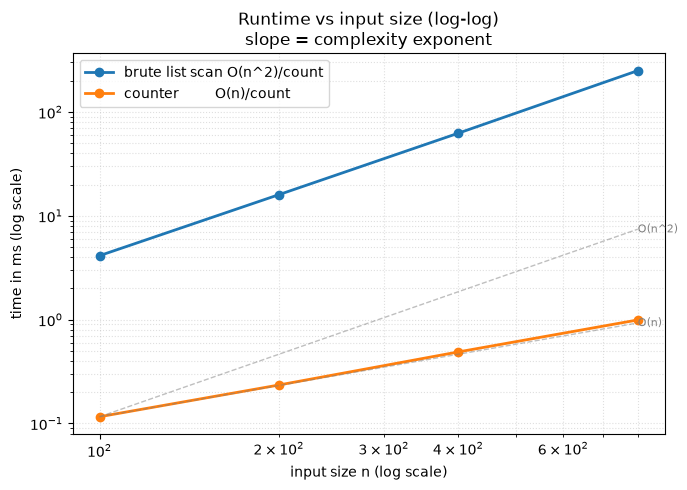

{'brute list scan O(n^2)/count': [4.132749978452921,
  15.990833984687924,
  62.50450003426522,
  250.1031659776345],
 'counter         O(n)/count  ': [0.11612498201429844,
  0.23479096125811338,
  0.4889169940724969,
  0.9933749679476023]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark   # shared: prints ratio table + optional log-log plot

def drive(cls, points, queries):
    ds = cls()
    for p in points:
        ds.add(p)
    return [ds.count(q) for q in queries]

def make_worst_case(n):
    points = [[i, i] for i in range(1, n + 1)] + [[0, i] for i in range(1, n + 1)] + [[i, 0] for i in range(1, n + 1)]
    return (points, [[0, 0]] * 3)              # each query: n squares, n diagonal candidates

assert drive(DetectSquares, *make_worst_case(50)) == drive(DetectSquaresBrute, *make_worst_case(50)) == [50] * 3

solutions = {
    "brute list scan O(n^2)/count": lambda pts, qs: drive(DetectSquaresBrute, pts, qs),
    "counter         O(n)/count  ": lambda pts, qs: drive(DetectSquares, pts, qs),
}
sizes = [100, 200, 400, 800]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Frequency Count](README.md) — count every added point in a `Counter`; `count` reads three corner counts per diagonal candidate and multiplies them.
- **Fix one anchor, derive the rest:** the query plus one diagonal corner determines the whole square, so the search is over one point, not over triples.
- **Duplicates mean multiply, not dedupe:** with `n` copies of the diagonal and `a`, `b` copies of the other corners there are `n·a·b` distinct squares. Loop over **distinct** keys and multiply by their counts.
- **Signal:** "duplicates are treated as different", "count the number of ways", points / pairs arriving in a stream with a query that asks how many matching shapes exist.
- **Related problems:** Valid Anagram (counts compared), Number of Boomerangs (count distances from an anchor), Max Points on a Line (count slopes from an anchor), 4Sum II (count pair sums, multiply).
- **Common pitfalls:**
  1. Counting the zero-area case: require `px != qx` as well as `|dx| == |dy|`.
  2. Using a `list` point as a dict key — convert to a `tuple`.
  3. Inserting while iterating: `cnt.get(k, 0)` or `Counter[...]` reads are safe; a `defaultdict` read would insert a new key and break the loop.
  4. Iterating the raw list of duplicates *and* multiplying by the count — that double-counts.